# Análisis exploratorio · The Spanish Fake News Corpus

Notebook de la Parte 2 (Jairo). Responde lo que pide la sección 5.1 del enunciado y la spec 10: distribución de clases, longitud de los textos, palabras más frecuentes y valores faltantes, más dos cosas propias de este corpus: los temas y las fuentes.

Cada sección termina con una **conclusión** y, cuando corresponde, con la decisión que se tomó en `params.yaml`.

Se ejecuta desde la carpeta `notebooks/` con el entorno del proyecto activado.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # para importar src/ desde notebooks/

import matplotlib.pyplot as plt
import pandas as pd

from src.config import ETIQUETAS, PARAMS
from src.data.cargar import cargar_crudo, cargar_procesado

pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "grid.alpha": 0.3})
COLORES = {"falsa": "#d1495b", "verdadera": "#2e86ab"}

crudo = cargar_crudo()          # los tres .xlsx tal como vienen (columnas ya en minúsculas)
df = cargar_procesado()         # data/processed/noticias.csv, contrato C2
print("crudo:", crudo.shape, "| procesado:", df.shape)

crudo: (1543, 8) | procesado: (1542, 5)


## 1. Registros antes y después de limpiar

In [2]:
resumen = pd.DataFrame({
    "noticias": [len(crudo), len(df)],
}, index=["crudo (3 archivos)", "procesado (noticias.csv)"])
resumen.loc["eliminadas"] = resumen.iloc[0] - resumen.iloc[1]
resumen

,noticias
crudo (3 archivos),1543
procesado (noticias.csv),1542
eliminadas,1


**Conclusión.** De 1.543 noticias se pierde **una sola**: un duplicado exacto. No hay textos vacíos. El corpus llega casi intacto al modelo.

## 2. Valores faltantes

In [3]:
faltantes = crudo.isna().sum().to_frame("faltantes")
faltantes["%"] = (faltantes["faltantes"] / len(crudo) * 100).round(1)
faltantes[faltantes["faltantes"] > 0]

,faltantes,%
source,7,0.5
headline,72,4.7
link,3,0.2


In [4]:
# ¿De qué versión son los titulares vacíos?
crudo.assign(sin_titular=crudo["headline"].isna()).groupby("anio")["sin_titular"].sum()

anio
2018     0
2021    72
Name: sin_titular, dtype: int64

**Conclusión.**

- `headline`: 72 titulares vacíos, **todos de la v2** (2020-21). Por eso `cargar.py` usa solo el cuerpo cuando falta el titular, en lugar de descartar la noticia.
- `source` (7) y `link` (3) faltan en pocas filas. Ninguna de las dos entra al modelo, así que no afectan.
- `text` y `category` (la etiqueta) no tienen faltantes.

## 3. Distribución de clases

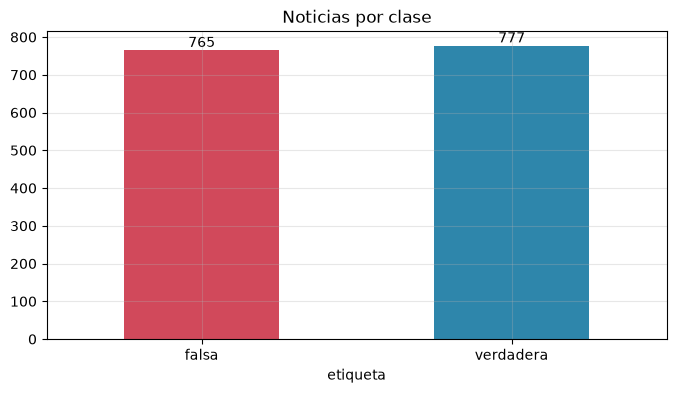

etiqueta
falsa        49.6
verdadera    50.4
Name: %, dtype: float64

In [5]:
conteo = df["etiqueta"].value_counts().reindex(ETIQUETAS)
ax = conteo.plot.bar(color=[COLORES[e] for e in conteo.index], rot=0)
ax.set_title("Noticias por clase")
ax.bar_label(ax.containers[0])
plt.show()
(conteo / len(df) * 100).round(1).rename("%")

In [6]:
# Por versión del corpus (v1 = 2018, v2 = 2020-21)
pd.crosstab(df["anio"], df["etiqueta"], margins=True)

etiqueta,falsa,verdadera,All
anio,,,
2018,479,491,970
2021,286,286,572
All,765,777,1542


**Conclusión.** 765 falsas (49,6 %) y 777 verdaderas (50,4 %): el corpus está **balanceado**, y también lo está cada versión por separado (479/491 y 286/286). Por eso:

- **No hace falta `class_weight`** ni sobremuestreo: las grillas de `params.yaml` ya no lo incluyen.
- La línea base (predecir siempre la clase mayoritaria) acierta solo la mitad: F1 macro ≈ 0,34. Cualquier modelo útil tiene que superarla con holgura.
- El split estratificado 80/20 mantiene esta proporción en train y test.

## 4. Longitud de los textos

In [7]:
df["palabras"] = df["texto"].str.split().str.len()
df["caracteres"] = df["texto"].str.len()

df.groupby("etiqueta")[["palabras", "caracteres"]].describe(percentiles=[0.01, 0.5, 0.95, 0.995]).T.round(0)

etiqueta            falsa  verdadera
palabras   count    765.0      777.0
           mean     347.0      537.0
           std      290.0      389.0
           min       28.0       51.0
           1%        54.0      115.0
           50%      283.0      436.0
           95%      671.0     1300.0
           99.5%   2146.0     2257.0
           max     4016.0     4017.0
caracteres count    765.0      777.0
           mean    2084.0     3284.0
           std     1774.0     2360.0
           min      173.0      326.0
           1%       339.0      683.0
           50%     1677.0     2613.0
           95%     4114.0     8000.0
           99.5%  12729.0    14138.0
           max    25872.0    24027.0

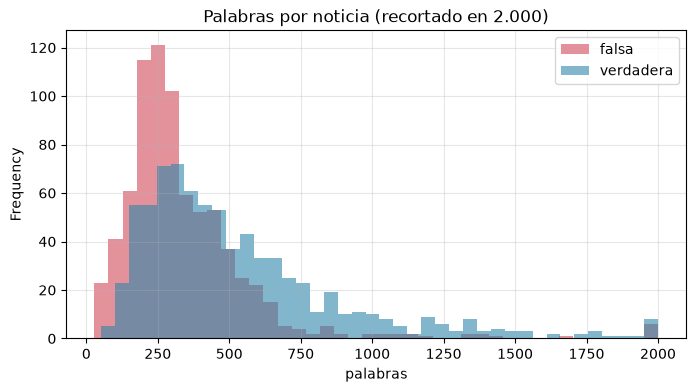

In [8]:
fig, ax = plt.subplots()
for etiqueta in ETIQUETAS:
    df.loc[df["etiqueta"] == etiqueta, "palabras"].clip(upper=2000).plot.hist(
        bins=40, alpha=0.6, ax=ax, label=etiqueta, color=COLORES[etiqueta])
ax.set_title("Palabras por noticia (recortado en 2.000)")
ax.set_xlabel("palabras")
ax.legend()
plt.show()

In [9]:
limites = PARAMS["api"]
print("noticia más corta:", df["palabras"].min(), "palabras")
print(f"noticias con menos de {limites['min_palabras']} palabras:", (df["palabras"] < limites["min_palabras"]).sum())
print("noticia más larga:", df["caracteres"].max(), "caracteres")
print(f"noticias con más de {limites['max_chars']} caracteres:", (df["caracteres"] > limites["max_chars"]).sum())

noticia más corta: 28 palabras
noticias con menos de 20 palabras: 0
noticia más larga: 25872 caracteres
noticias con más de 20000 caracteres: 2


**Conclusión.**

- Las **falsas son más cortas**: mediana de 283 palabras frente a 436 de las verdaderas. Las verdaderas tienen una cola larga (el 5 % supera las 1.300 palabras): son notas de agencia y reportajes. La longitud es una diferencia de **estilo**, no de veracidad. TF-IDF normaliza cada vector, así que el modelo no la usa directamente.
- **`min_palabras: 20`** (API): la noticia más corta del corpus tiene 28 palabras, así que el mínimo no rechaza ninguna noticia real y sí frena textos sin contenido suficiente para decidir.
- **`max_chars: 20000`** (API): solo 2 de 1.542 noticias lo superan (la más larga tiene 25.872 caracteres). Cubre el 99,9 % del corpus y evita textos desmedidos.